# Evaluations

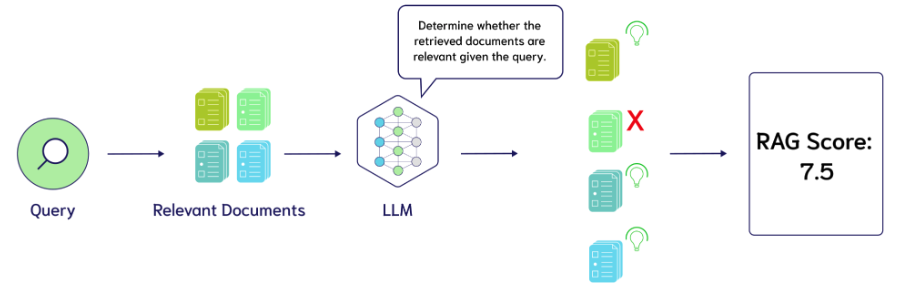

## RAG

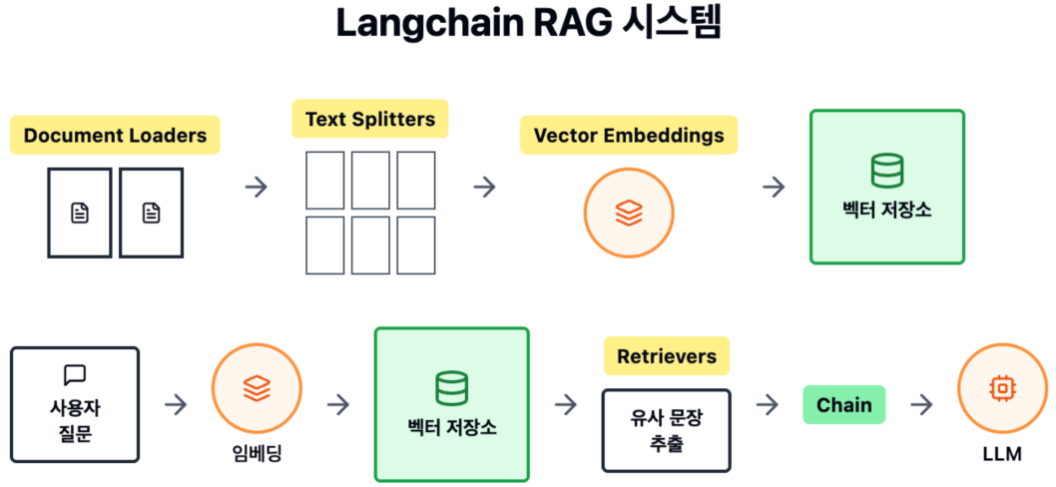

### 단계 1: 문서 로드(Load Documents)

In [1]:
from langchain_community.document_loaders import PDFPlumberLoader

loader = PDFPlumberLoader("./data/SPRI_AI_Brief_2023년12월호_F.pdf")
docs = loader.load()

In [2]:
print(f"pdf 페이지 수: {len(docs)}")

pdf 페이지 수: 23


### 단계 2: 문서 분할(Split Documents)

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500, chunk_overlap=50)
split_documents = text_splitter.split_documents(docs)

In [4]:
print(f"저장될 문서의 수: {len(split_documents)}")

저장될 문서의 수: 72


### 단계 3: 임베딩(Embedding) 생성
- [OpenAI Key 발급](https://platform.openai.com/api-keys)

In [5]:
from dotenv import load_dotenv 

load_dotenv()

True

In [6]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

### 단계 4: Qdrant Vector DB 생성 및 저장

로컬 Qdrant는 `qdrant/` 폴더에서 `docker compose up -d`로 실행한 뒤 사용합니다.


In [7]:
from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient

QDRANT_URL = "http://localhost:6333"
COLLECTION_NAME = "evaluation"

# 재실행 시 같은 문서가 중복 저장되지 않도록 기존 Qdrant 컬렉션을 초기화합니다.
qdrant_client = QdrantClient(url=QDRANT_URL)
if qdrant_client.collection_exists(collection_name=COLLECTION_NAME):
    qdrant_client.delete_collection(collection_name=COLLECTION_NAME)

vectorstore = QdrantVectorStore.from_documents(
    documents=split_documents,  # 문서 리스트
    embedding=embeddings,  # 임베딩 함수
    url=QDRANT_URL,  # Qdrant 서버 주소
    collection_name=COLLECTION_NAME,  # 컬렉션 이름
)


In [8]:
stats = qdrant_client.count(
    collection_name=COLLECTION_NAME,
    exact=True,
).count

print(f"현재 문서 수: {stats}")


현재 문서 수: 72


#### [Qdrant 접속](http://localhost:6333/dashboard#/collections)

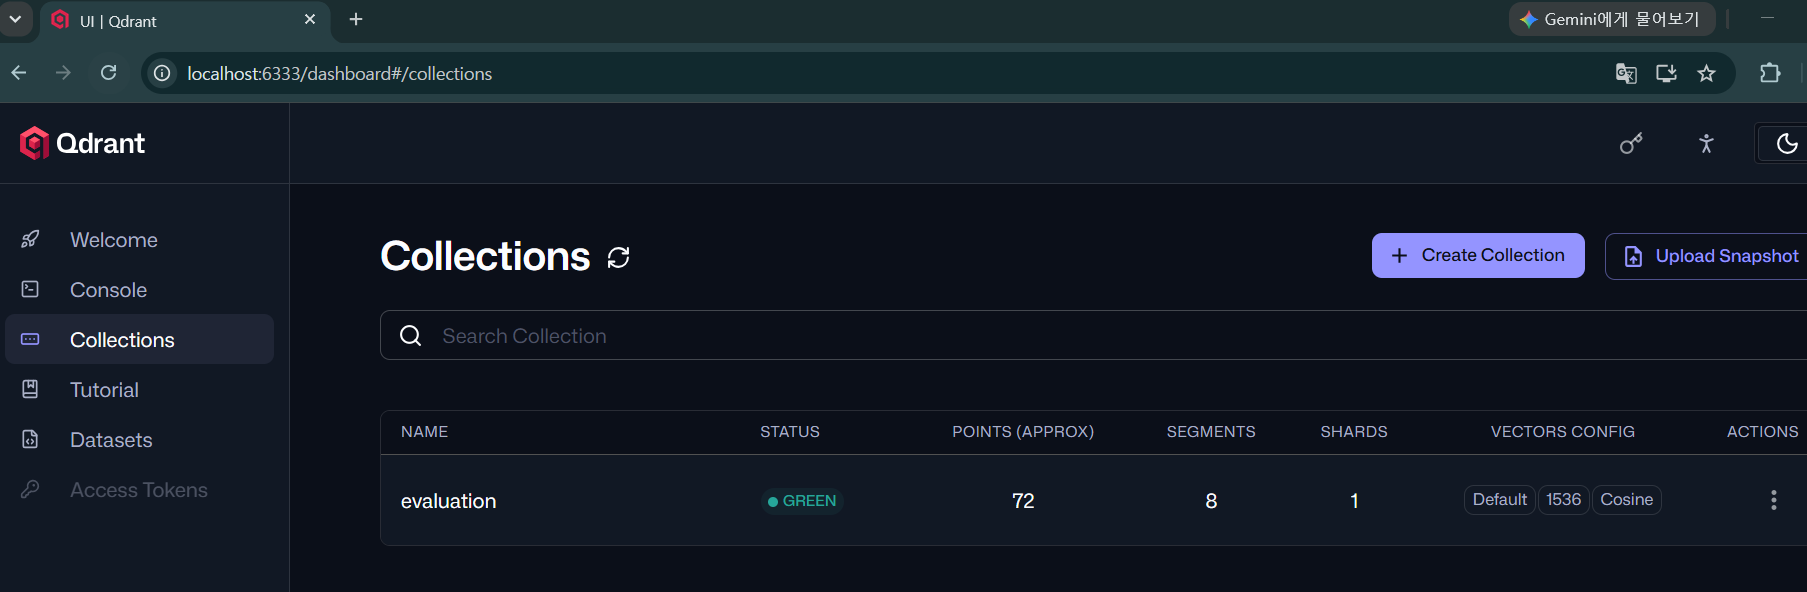

### 단계 5: 검색기(Retriever) 생성

#### 검색 개수(k) 설정

`k`를 늘리면 정답 근거가 포함될 가능성은 커지지만, 관련 없는 문맥도 함께 들어와 `context_precision`이 낮아질 수 있습니다. 이후 3번 노트북에서 `k=2`, `k=4`, `k=8` 결과를 비교해 봅니다.


In [9]:
# 문서에 포함되어 있는 정보를 검색하고 생성합니다.
RETRIEVER_K = 4
retriever = vectorstore.as_retriever(search_kwargs={"k": RETRIEVER_K})

print(f"검색 문맥 수(k): {RETRIEVER_K}")


검색 문맥 수(k): 4


### 단계 6: 프롬프트 생성(Create Prompt)

In [10]:
from langchain_core.prompts import PromptTemplate

# 프롬프트를 생성합니다.
prompt = PromptTemplate.from_template(
    template="""
    - 당신은 질의응답 작업을 위한 어시스턴트입니다.
    - 아래에 제공된 검색/추출된 컨텍스트를 활용하여 질문에 답하십시오.
    - 답을 모를 경우, 모른다고 말하십시오.
    - 반드시 한국어로 답변해야 합니다.

    #컨텍스트:
    {context}

    #질문:
    {question}
    """
)


In [11]:
prompt.input_variables

['context', 'question']

### 단계7: RAG 체인 생성


#### LLM을 통한 답변 생성

In [12]:
from langchain_ollama.chat_models import ChatOllama 

# 언어모델(LLM) 생성
llm = ChatOllama(
    model="gemma3:4b",
    temperature=0.1,
    top_p=1.0,
    num_predict=256,
    keep_alive="5m"
)

#### 체인 생성 

In [13]:
from langchain_core.output_parsers import StrOutputParser

def get_answer_of_llm(dict_param:dict):
    contexts = [
        doc.page_content for doc in dict_param["context"]
    ]

    answer = (prompt | llm | StrOutputParser()).invoke({
        "context" : "\n".join(contexts),
        "question": dict_param["question"]
    })

    return {
        "context": contexts,
        "question": dict_param["question"],
        "answer": answer
    }

In [14]:
from langchain_core.runnables import RunnablePassthrough, RunnableLambda

chain = (
    {
        "context": retriever, 
        "question": RunnablePassthrough()
    }
    | RunnableLambda(get_answer_of_llm)
)
    

### 단계8: 답변 추가 및 저장

#### 질문 로드

- evaluation_questions_for_ragas 데이터 로드 

In [15]:
import pandas as pd 

df_evaluation_ragas = pd.read_csv("./data/evaluation_questions_for_ragas.csv")

print(f"(평가 데이터의 수, 평가 데이터의 컬럼 수): {df_evaluation_ragas.shape }")

(평가 데이터의 수, 평가 데이터의 컬럼 수): (15, 8)


| 컬럼명 | 설명 | 데이터 타입 | 예시 값 |
|--------|------|------------|---------|
| **user_input** | 사용자가 입력한 질문(쿼리) | `str` | "바이든 대통령이 발표한 AI 행정명령의 주요 내용은 뭐고, 그 목적은 무엇인지 설명해줘." |
| **reference_contexts** | RAG 시스템이 검색해야 할 참조 문서(문맥) 리스트. 문자열로 저장된 리스트 형태 | `str` (리스트 문자열) | "['1. 정책/법제 2. 기업/산업...']" |
| **reference** | 해당 질문에 대한 정답(ground truth). RAG 시스템이 생성해야 하는 이상적인 답변 | `str` | "바이든 대통령이 발표한 AI 행정명령은 안전하고 신뢰할 수 있는 AI 개발과 사용을 보장하기 위한 것으로..." |
| **persona_name** | 질문 생성 시 사용된 페르소나 이름 | `str` | "AI Specialist" |
| **query_style** | 질문의 문법/스타일 또는 수동 hard case 유형 | `str` | "PERFECT_GRAMMAR", "CONDITIONAL_REASONING", "OUT_OF_DOMAIN_CORPUS" |
| **query_length** | 질문의 길이 분류 | `str` | "LONG", "SHORT" |
| **synthesizer_name** | 질문을 만든 RAGAS synthesizer 또는 수동 케이스 이름 | `str` | "multi_hop_specific_query_synthesizer", "manual_hard_case" |
| **query_category** | 분포 확인을 위한 질문 범주 | `str` | "single_hop_specific", "multi_hop_abstract", "out_of_domain" |

In [16]:
df_evaluation_ragas.head(2)

,user_input,reference_contexts,reference,persona_name,query_style,query_length,synthesizer_name,query_category
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,"['1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n 미국, 안전...",바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령...,AI Policy Analyst,WEB_SEARCH_LIKE,MEDIUM,single_hop_specific_query_synthesizer,single_hop_specific
1,주택 관련해서 AI가 어떻게 사용되나?,['형평성과 시민권 향상 △소비자\n보호 △노동자 지원 △혁신과 경쟁 촉진 △국제협...,형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기...,AI Policy Analyst,POOR_GRAMMAR,SHORT,single_hop_specific_query_synthesizer,single_hop_specific


#### RAG 답변 생성 

- `batch()` 를 호출하여 배치 데이터셋에 대한 답변을 받습니다.

In [17]:
question_dataset = [question for question in df_evaluation_ragas["user_input"]]
question_dataset[:3]

['바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?',
 '주택 관련해서 AI가 어떻게 사용되나?',
 'NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?']

In [18]:
results = chain.batch(question_dataset)

In [19]:
print(f"총 데이터의 수: {len(results)}")

총 데이터의 수: 15


In [20]:
print(f"생성된 데이터는 {results[0].keys()}")

생성된 데이터는 dict_keys(['context', 'question', 'answer'])


In [21]:
type(results[0]['context'])

list

- `answer`: RAG를 통한 LLM 답변 
- `context`: VectorDB에서 추출한 근거 데이터 

In [22]:
df_evaluation_ragas['response'] = [ result['answer'] for result in results ]
df_evaluation_ragas['retrieved_contexts'] = [ result['context'] for result in results ]

- `user_input`: RAGAS를 통해 생성된 테스트 질문 
- `reference`: RAGAS를 통해 생성된 테스트 질문에 대한 정답 답변 

In [23]:
# RAGAS 0.3.9 평가 API가 요구하는 컬럼명을 유지합니다.
# user_input, response, retrieved_contexts, reference
df_evaluation_ragas.head(2)

,user_input,reference_contexts,reference,persona_name,query_style,query_length,synthesizer_name,query_category,response,retrieved_contexts
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,"['1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n 미국, 안전...",바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령...,AI Policy Analyst,WEB_SEARCH_LIKE,MEDIUM,single_hop_specific_query_synthesizer,single_hop_specific,"바이든 대통령의 행정명령은 AI의 안전과 보안 기준 마련, 개인정보 보호, 형평성과...","[1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n미국, 안전하고..."
1,주택 관련해서 AI가 어떻게 사용되나?,['형평성과 시민권 향상 △소비자\n보호 △노동자 지원 △혁신과 경쟁 촉진 △국제협...,형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기...,AI Policy Analyst,POOR_GRAMMAR,SHORT,single_hop_specific_query_synthesizer,single_hop_specific,"제공된 컨텍스트에 따르면, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지...",[문제를 방지하는 조치를 확대\n∙ 형사사법 시스템에서 AI 사용 모범사례를 개발하...


#### 필요한 컬럼만 추출 
- `response`: RAG를 통한 LLM 답변 
- `retrieved_contexts`: VectorDB에서 추출한 근거 데이터 
- `user_input`: RAGAS를 통해 생성된 테스트 질문 
- `reference`: RAGAS를 통해 생성된 테스트 질문에 대한 정답 답변 
- `reference_contexts`: RAGAS를 통해 생성된 정답 답변의 근거 데이터 

In [24]:
df_evaluation_ragas_with_answer = df_evaluation_ragas[
    ['user_input', 'retrieved_contexts', 'response', 'reference', 'reference_contexts']
].copy()


In [25]:
df_evaluation_ragas_with_answer.head(2)

,user_input,retrieved_contexts,response,reference,reference_contexts
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,"[1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n미국, 안전하고...","바이든 대통령의 행정명령은 AI의 안전과 보안 기준 마련, 개인정보 보호, 형평성과...",바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령...,"['1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n 미국, 안전..."
1,주택 관련해서 AI가 어떻게 사용되나?,[문제를 방지하는 조치를 확대\n∙ 형사사법 시스템에서 AI 사용 모범사례를 개발하...,"제공된 컨텍스트에 따르면, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지...",형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기...,['형평성과 시민권 향상 △소비자\n보호 △노동자 지원 △혁신과 경쟁 촉진 △국제협...


#### RAG 답변 저장

In [26]:
import json

df_evaluation_ragas_with_answer['retrieved_contexts'] = df_evaluation_ragas_with_answer['retrieved_contexts'].apply(json.dumps)

df_evaluation_ragas_with_answer.head(2)

,user_input,retrieved_contexts,response,reference,reference_contexts
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,"[""1. \uc815\ucc45/\ubc95\uc81c 2. \uae30\uc5c5...","바이든 대통령의 행정명령은 AI의 안전과 보안 기준 마련, 개인정보 보호, 형평성과...",바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령...,"['1. 정책/법제 2. 기업/산업 3. 기술/연구 4. 인력/교육\n 미국, 안전..."
1,주택 관련해서 AI가 어떻게 사용되나?,"[""\ubb38\uc81c\ub97c \ubc29\uc9c0\ud558\ub294 ...","제공된 컨텍스트에 따르면, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지...",형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기...,['형평성과 시민권 향상 △소비자\n보호 △노동자 지원 △혁신과 경쟁 촉진 △국제협...


In [27]:
df_evaluation_ragas_with_answer.to_csv("./data/evaluation_answers_from_rag.csv", index=False, header=True)
